# Ejercicio 02 · Ensambles, reducción dimensional y Green AI

**Autora:** Kimberly Pereyra · INF-8239 Ciencia de Datos II

**Protocolo congelado (igual que el Ejercicio 01)**
- Dataset: *Predict Students' Dropout and Academic Success* (UCI 697, CC BY 4.0).
- Target: `Target` (Dropout, Enrolled, Graduate). Se excluyen las 6 variables del 2º semestre por fuga temporal.
- Partición: 80/20 estratificada, `random_state=42` (la misma del Ejercicio 01). La prueba solo se usa para la evaluación final.
- **Métrica principal:** F1 macro. **Clase prioritaria:** Dropout (se reporta su recall).
- Todos los modelos usan el mismo preprocesamiento y `class_weight="balanced"` para que la comparación sea homogénea.
- Las SVM se entrenan sin `probability=True`: no se necesitan probabilidades y esa opción multiplica el tiempo de ajuste.

In [3]:
import sys
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
REPORTS = ROOT / "reports"
(REPORTS / "models").mkdir(parents=True, exist_ok=True)

from inf8239_u01.data import download_csv, load_data, DEFAULT_PATH
from inf8239_u01.features import split_xy, train_test, build_preprocess

if not DEFAULT_PATH.exists():
    download_csv()
df = load_data()
X, y = split_xy(df)
Xtr, Xte, ytr, yte = train_test(X, y)
preprocess = build_preprocess(X)
print(X.shape, Xtr.shape, Xte.shape)

(4424, 30) (3539, 30) (885, 30)


In [4]:
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

models = {
    "logistic": Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "svm_c1": Pipeline([("prep", preprocess), ("model", SVC(C=1, gamma="scale", class_weight="balanced", random_state=42))]),
    "svm_c10": Pipeline([("prep", preprocess), ("model", SVC(C=10, gamma=0.01, class_weight="balanced", random_state=42))]),
    "svm_c10_pca": Pipeline([("prep", preprocess), ("pca", PCA(n_components=0.95, random_state=42)),
                             ("model", SVC(C=10, gamma=0.01, class_weight="balanced", random_state=42))]),
    "rf_100": Pipeline([("prep", preprocess), ("model", RandomForestClassifier(n_estimators=100, max_depth=8, class_weight="balanced", random_state=42, n_jobs=-1))]),
    "rf_300": Pipeline([("prep", preprocess), ("model", RandomForestClassifier(n_estimators=300, max_depth=8, class_weight="balanced", random_state=42, n_jobs=-1))]),
    "boost": Pipeline([("prep", preprocess), ("model", HistGradientBoostingClassifier(max_depth=6, class_weight="balanced", random_state=42))]),
}
print(len(models), "configuraciones")

7 configuraciones


In [5]:
from time import perf_counter
import joblib, numpy as np
from sklearn.metrics import f1_score, recall_score

rows = []
for name, model in models.items():
    fit_times = []
    for repetition in range(3):
        start = perf_counter(); model.fit(Xtr, ytr)
        fit_times.append(perf_counter() - start)
    start = perf_counter(); pred = model.predict(Xte)
    predict_ms = (perf_counter() - start) * 1000
    path = REPORTS / "models" / f"{name}.joblib"
    joblib.dump(model, path)
    rows.append({"model": name,
                 "f1_macro": f1_score(yte, pred, average="macro"),
                 "recall_macro": recall_score(yte, pred, average="macro"),
                 "recall_dropout": recall_score(yte, pred, labels=["Dropout"], average="macro"),
                 "fit_median_s": np.median(fit_times),
                 "predict_ms": predict_ms,
                 "size_kb": path.stat().st_size / 1024})
    print(f"{name}: listo")
results = pd.DataFrame(rows)
results.sort_values("f1_macro", ascending=False).round(4)

logistic: listo
svm_c1: listo
svm_c10: listo
svm_c10_pca: listo
rf_100: listo
rf_300: listo
boost: listo


,model,f1_macro,recall_macro,recall_dropout,fit_median_s,predict_ms,size_kb
5,rf_300,0.6781,0.6871,0.6761,0.4904,52.9243,5285.6592
4,rf_100,0.6695,0.6778,0.6585,0.1875,32.5903,1818.8154
2,svm_c10,0.6677,0.6745,0.6655,0.5564,172.1580,4021.4355
1,svm_c1,0.6675,0.6777,0.6268,0.6532,194.3109,4602.2012
6,boost,0.6661,0.6698,0.6972,2.8322,22.2988,815.5176
0,logistic,0.6593,0.6677,0.6831,0.2074,6.7798,13.8691
3,svm_c10_pca,0.6517,0.6621,0.6197,0.3212,115.0193,971.3730


Dimensiones tras preprocesar: 230 | Componentes para 95 %: 46
Varianza PC1 + PC2: 22.7 %


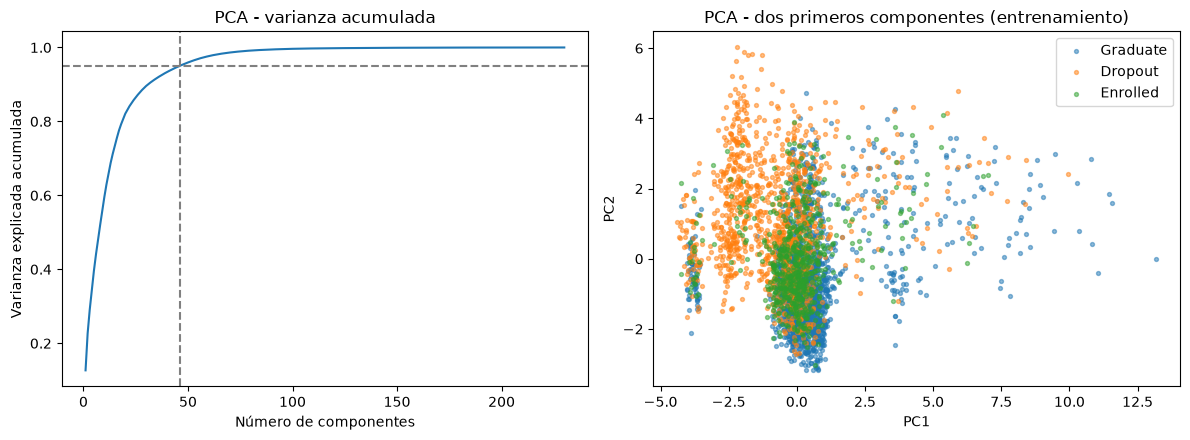

In [6]:
import matplotlib.pyplot as plt
from sklearn.base import clone

prep_fit = clone(preprocess).fit(Xtr)
Ztr = prep_fit.transform(Xtr)
pca_full = PCA(random_state=42).fit(Ztr)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.argmax(cum >= 0.95) + 1)
print("Dimensiones tras preprocesar:", Ztr.shape[1], "| Componentes para 95 %:", n95)
print("Varianza PC1 + PC2:", round(cum[1] * 100, 1), "%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(range(1, len(cum) + 1), cum)
axes[0].axhline(0.95, ls="--", c="gray"); axes[0].axvline(n95, ls="--", c="gray")
axes[0].set(xlabel="Número de componentes", ylabel="Varianza explicada acumulada", title="PCA - varianza acumulada")
Z2 = pca_full.transform(Ztr)[:, :2]
for cls in ["Graduate", "Dropout", "Enrolled"]:
    m = (ytr == cls).values
    axes[1].scatter(Z2[m, 0], Z2[m, 1], s=8, alpha=0.5, label=cls)
axes[1].set(xlabel="PC1", ylabel="PC2", title="PCA - dos primeros componentes (entrenamiento)")
axes[1].legend()
plt.tight_layout(); plt.savefig(REPORTS / "pca.png", dpi=160); plt.show()

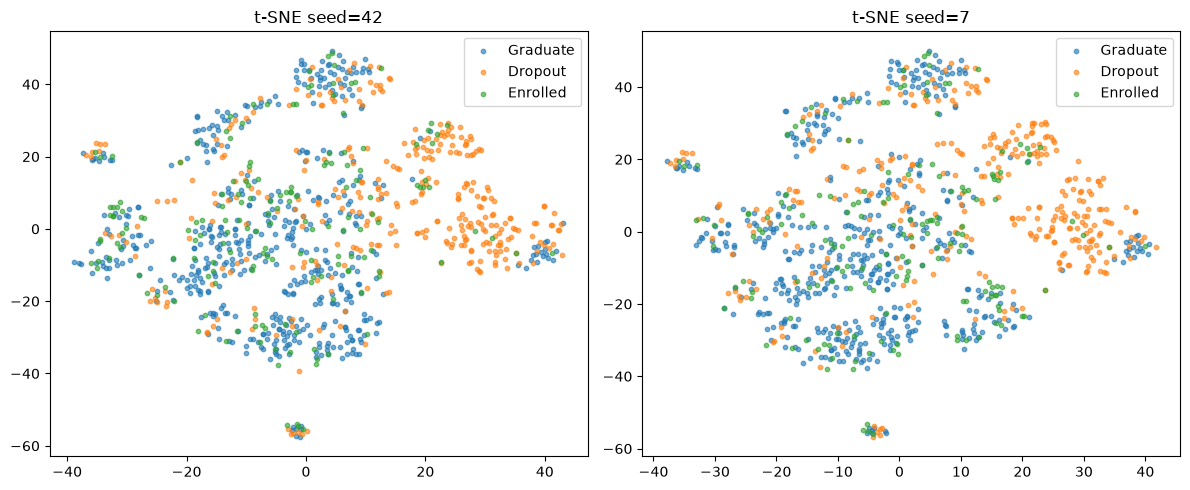

In [7]:
from sklearn.manifold import TSNE

sample_idx = Xtr.sample(min(1000, len(Xtr)), random_state=42).index
scaled = prep_fit.transform(Xtr.loc[sample_idx])
y_sample = ytr.loc[sample_idx]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, seed in zip(axes, [42, 7]):
    emb = TSNE(n_components=2, perplexity=30, random_state=seed, init="pca", learning_rate="auto").fit_transform(scaled)
    for cls in ["Graduate", "Dropout", "Enrolled"]:
        m = (y_sample == cls).values
        ax.scatter(emb[m, 0], emb[m, 1], s=10, alpha=0.6, label=cls)
    ax.set_title(f"t-SNE seed={seed}")
    ax.legend()
plt.tight_layout(); plt.savefig(REPORTS / "tsne_two_seeds.png", dpi=160); plt.show()

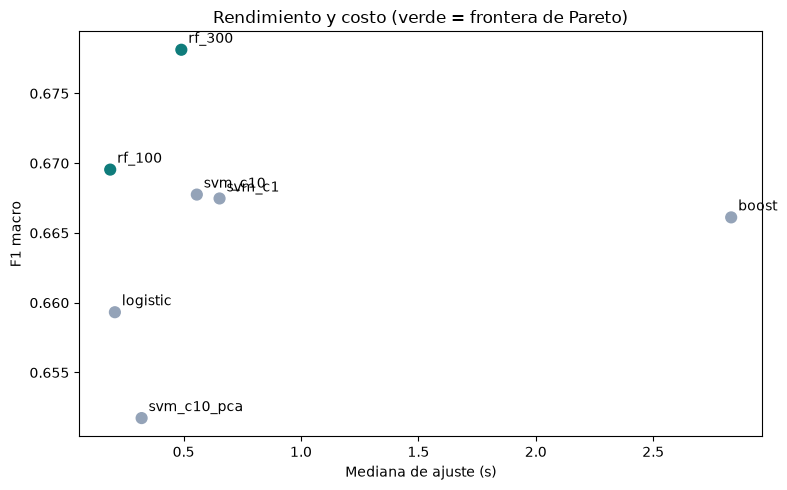

,model,f1_macro,recall_macro,recall_dropout,fit_median_s,predict_ms,size_kb,is_pareto
5,rf_300,0.6781,0.6871,0.6761,0.4904,52.9243,5285.6592,True
4,rf_100,0.6695,0.6778,0.6585,0.1875,32.5903,1818.8154,True
2,svm_c10,0.6677,0.6745,0.6655,0.5564,172.1580,4021.4355,False
1,svm_c1,0.6675,0.6777,0.6268,0.6532,194.3109,4602.2012,False
6,boost,0.6661,0.6698,0.6972,2.8322,22.2988,815.5176,False
0,logistic,0.6593,0.6677,0.6831,0.2074,6.7798,13.8691,False
3,svm_c10_pca,0.6517,0.6621,0.6197,0.3212,115.0193,971.3730,False


In [8]:
from inf8239_u01.green import pareto_flags

results["is_pareto"] = pareto_flags(results)
results.to_csv(REPORTS / "green_ai_results.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(results.fit_median_s, results.f1_macro, c=results.is_pareto.map({True: "#0f7c7b", False: "#94a3b8"}), s=60)
for _, r in results.iterrows():
    ax.annotate(r.model, (r.fit_median_s, r.f1_macro), textcoords="offset points", xytext=(5, 5))
ax.set(xlabel="Mediana de ajuste (s)", ylabel="F1 macro", title="Rendimiento y costo (verde = frontera de Pareto)")
plt.tight_layout(); plt.savefig(REPORTS / "pareto.png", dpi=160); plt.show()
results.sort_values(["is_pareto", "f1_macro"], ascending=[False, False]).round(4)

In [9]:
import platform, sklearn
print("Python", sys.version)
print("Sistema", platform.platform())
print("Procesador", platform.processor())
print("scikit-learn", sklearn.__version__)

Python 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Sistema Windows-10-10.0.26300-SP0
Procesador Intel64 Family 6 Model 186 Stepping 3, GenuineIntel
scikit-learn 1.9.1
